# 00 · Proyecto Integrador: Riesgo de crédito de punta a punta

**Predicción de la probabilidad de impago (PD) de clientes a partir de información financiera, demográfica y textual.**

| | |
|---|---|
| **IDs del enunciado que cubre** | **PF1** (notebook que predice la probabilidad de impago), **E2** (todas las fases del proceso analítico), **E4** (integración de los módulos de Programación e IA), **R2** (análisis de datos, IA y NLP); recorre **F1 → F5** |
| **Fuente de datos** | `db/credit_risk.csv` (12.144 solicitudes, 21 columnas, objetivo `default`) |

Este notebook es **autocontenido**: repite de forma compacta las piezas clave de cada fase (limpieza, modelado, evaluación) y, cuando existen, lee los artefactos generados por los notebooks 01–09. Al final, la función `predecir_cliente(dict)` devuelve la PD y la banda de riesgo de un cliente nuevo y, si la API local está corriendo, la consulta también.

### Mapa: ID del enunciado → sección

| ID | Descripción | Sección de este notebook | Notebook detallado |
|---|---|---|---|
| F1, IA1.1, IA1.3, E5 | Definir el problema y análisis ético | §1 | 01 |
| F2, P1.1–P1.5, IA1.2 | Exploración inicial y EDA | §2.1 | 02, 04 |
| F2, P2.1–P2.6, IA2.4, IA2.5 | Limpieza, variables nuevas, atípicos, split | §2.2 | 03, 04 |
| F3, IA3.3, R1 | Modelos clásicos (LR, HistGradientBoosting) | §3.1 | 05 |
| F3, IA3.2, IA3.E2 | Redes neuronales (MLP, CNN 1D, LSTM) | §3.2 (resultados) | 06 |
| F3, IA3.1, IA3.E1, R2 | NLP: TF-IDF, sentimiento BERT, embeddings BERT/GPT | §3.2 (resultados) | 07 |
| F4, IA1.3 | Calibración, umbral por costo, bandas, equidad | §4 | 08 |
| IA3.6 | Big Data con Spark | §5 (referencia) | 09 |
| F5, IA3.4, IA3.5, IA3.E3, R4 | Predicción de un cliente y consumo de la API | §5 | API en `Back/api/` |
| PF1, E2, E4 | Integración y comunicación de resultados | §5 y Conclusiones | — |

## 0. Configuración del entorno

In [1]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 60
plt.rcParams["figure.dpi"] = 100

def encontrar_raiz():
    """Sube desde el directorio actual hasta encontrar db/credit_risk.csv (sin rutas absolutas)."""
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "db" / "credit_risk.csv").exists():
            return carpeta
    raise FileNotFoundError("No se encontró db/credit_risk.csv. Ejecute el notebook desde Back/notebooks.")

RAIZ = encontrar_raiz()
DATA_PATH = RAIZ / "db" / "credit_risk.csv"
MODELS_DIR = RAIZ / "Back" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATA_PATH.relative_to(RAIZ), "| artefactos:", MODELS_DIR.relative_to(RAIZ))

Dataset: db\credit_risk.csv | artefactos: Back\models


In [2]:
TARGET = "default"
TEXTO = "texto_solicitud"
SENSIBLES = ["sexo"]   # solo para auditar equidad, NUNCA como predictor
NUM_BASE = ["edad", "antiguedad_laboral_anios", "personas_a_cargo", "ingreso_mensual", "monto_credito",
            "plazo_meses", "tasa_interes_anual", "num_creditos_activos", "moras_ultimos_12m",
            "relacion_deuda_ingreso", "puntaje_buro", "uso_cupo_tarjetas"]
CAT_COLS = ["estado_civil", "nivel_educativo", "situacion_laboral", "tipo_vivienda", "proposito"]
NUEVAS = ["cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso", "tiene_moras_previas", "longitud_texto"]
NUM_FEATS = NUM_BASE + NUEVAS
FEATURES = NUM_FEATS + CAT_COLS

def limpiar(df_raw, verbose=True):
    """Duplicados (exactos y por id_cliente), valores inválidos -> NaN y texto vacío.
    La imputación (mediana/moda) y el capping p1-p99 se hacen en `preparar`, con estadísticos de train."""
    df = df_raw.copy()
    n0 = len(df)
    df = df.drop_duplicates()
    n1 = len(df)
    df = df.drop_duplicates(subset="id_cliente", keep="first")
    n2 = len(df)
    df = df[df[TARGET].isin([0, 1])].copy()
    df[TARGET] = df[TARGET].astype(int)
    df.loc[~df["edad"].between(18, 100), "edad"] = np.nan          # edades imposibles (1, 999...)
    for c in ["ingreso_mensual", "monto_credito"]:
        df.loc[df[c] <= 0, c] = np.nan
    for c in CAT_COLS + ["sexo"]:
        df[c] = df[c].where(df[c].isna(), df[c].astype(str).str.strip())
    df[TEXTO] = df[TEXTO].fillna("").astype(str)
    if verbose:
        print(f"Filas originales: {n0:,} | duplicados exactos: {n0 - n1} | duplicados por id_cliente: {n1 - n2} | filas finales: {len(df):,}")
    return df.reset_index(drop=True)

def agregar_variables(df):
    """Variables de negocio del paso 3: cuota (amortización francesa), ratios, moras previas y longitud del texto."""
    df = df.copy()
    r = df["tasa_interes_anual"] / 100 / 12
    n = df["plazo_meses"]
    df["cuota_estimada"] = df["monto_credito"] * r / (1 - (1 + r) ** (-n))
    df["ratio_cuota_ingreso"] = df["cuota_estimada"] / df["ingreso_mensual"]
    df["ratio_monto_ingreso"] = df["monto_credito"] / df["ingreso_mensual"]
    df["tiene_moras_previas"] = (df["moras_ultimos_12m"] > 0).astype(int)
    df["longitud_texto"] = df[TEXTO].str.len()
    return df

def preparar(df_limpio, test_size=0.2):
    """Split estratificado ANTES de imputar/capar: medianas, modas y percentiles salen solo de train (sin leakage)."""
    train, test = train_test_split(df_limpio, test_size=test_size, stratify=df_limpio[TARGET],
                                   random_state=RANDOM_STATE)
    train, test = train.copy(), test.copy()
    medianas = train[NUM_BASE].median()
    modas = {c: train[c].mode().iloc[0] for c in CAT_COLS}
    p01, p99 = train[NUM_BASE].quantile(0.01), train[NUM_BASE].quantile(0.99)
    preparar.stats = {"medianas": medianas, "modas": modas, "p01": p01, "p99": p99}
    salida = []
    for d in (train, test):
        d[NUM_BASE] = d[NUM_BASE].fillna(medianas).clip(lower=p01, upper=p99, axis=1)
        for c in CAT_COLS:
            d[c] = d[c].fillna(modas[c])
        salida.append(agregar_variables(d).reset_index(drop=True))
    return salida[0], salida[1]

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def build_preprocessor(extra_num=()):
    """Mismo preprocesador del paso 3: numéricas (mediana + StandardScaler) y categóricas (moda + One-Hot)."""
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_FEATS + list(extra_num)), ("cat", cat, CAT_COLS)])

In [4]:
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, brier_score_loss, roc_curve, precision_recall_curve,
                             confusion_matrix)

def ks_stat(y, p):
    """Estadístico KS: máxima separación entre las distribuciones acumuladas de buenos y malos."""
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def metricas(y, p, umbral=0.5):
    pred = (np.asarray(p) >= umbral).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "ks": ks_stat(y, p),
            "brier": brier_score_loss(y, p)}

## 1. F1 · Definición del problema

- **Contexto de negocio:** una entidad financiera debe decidir si **aprueba, revisa o rechaza** una solicitud de crédito. El usuario del modelo es el **analista de crédito**.
- **Formulación técnica:** clasificación binaria supervisada; objetivo `default` (1 = impago). La salida es una **probabilidad** de impago y una **banda de riesgo** (Bajo / Medio / Alto).
- **Costo de los errores:** un falso negativo (aprobar a quien no paga) cuesta el capital prestado; un falso positivo (rechazar a un buen cliente) cuesta el margen no ganado. Se asume **FN = 4 × FP**.
- **Métricas:** ROC-AUC (principal, meta ≥ 0.70), recall de impagos, F1, KS y Brier.
- **Ética:** `sexo` **no** se usa como predictor (solo para auditar); se mide el *disparate impact* (≥ 0.8) por sexo y edad; los IDs se tratan como seudónimos (Ley 1581 de 2012).

In [5]:
df_raw = pd.read_csv(DATA_PATH)
print("Forma del dataset:", df_raw.shape)
print(f"Tasa de impago observada: {df_raw[TARGET].mean():.3f}")
df_raw.head(3)

Forma del dataset: (12144, 21)
Tasa de impago observada: 0.356


,id_cliente,edad,sexo,estado_civil,nivel_educativo,situacion_laboral,antiguedad_laboral_anios,personas_a_cargo,tipo_vivienda,ingreso_mensual,monto_credito,plazo_meses,tasa_interes_anual,proposito,num_creditos_activos,moras_ultimos_12m,relacion_deuda_ingreso,puntaje_buro,uso_cupo_tarjetas,texto_solicitud,default
0,CLI_006413,23,M,Union_libre,Tecnico,Pensionado,5.0000,4,Arriendo,"1,840,000.0000","10,634,000.0000",12,34.1000,Consolidacion_deuda,0,1,0.5640,805.0000,0.2820,Quisiera acceder a financiacion para reorganiz...,0
1,CLI_008728,79,F,Casado,Secundaria,Empleado,56.8000,3,Propia,"3,954,000.0000","14,842,000.0000",24,13.8000,Libre_inversion,4,0,0.4700,738.0000,0.5550,Necesito el prestamo para una inversion person...,0
2,CLI_002268,63,F,Union_libre,Primaria,Independiente,7.0000,3,Propia,"1,187,000.0000","3,943,000.0000",6,14.2000,Libre_inversion,2,0,0.5190,779.0000,0.7500,Requiero el prestamo para cubrir gastos person...,0


## 2. F2 · Explorar y preparar los datos

### 2.1 Calidad de datos y exploración rápida

In [6]:
calidad = pd.DataFrame({"nulos": df_raw.isna().sum(), "pct_nulos": df_raw.isna().mean() * 100})
print("Duplicados por id_cliente:", int(df_raw["id_cliente"].duplicated().sum()))
print("Edades fuera de 18-100:", int((~df_raw["edad"].between(18, 100)).sum()))
calidad[calidad["nulos"] > 0].round(2)

Duplicados por id_cliente: 144
Edades fuera de 18-100: 25


,nulos,pct_nulos
situacion_laboral,494,4.0700
antiguedad_laboral_anios,1118,9.2100
tipo_vivienda,387,3.1900
ingreso_mensual,749,6.1700
relacion_deuda_ingreso,612,5.0400
puntaje_buro,488,4.0200
texto_solicitud,240,1.9800


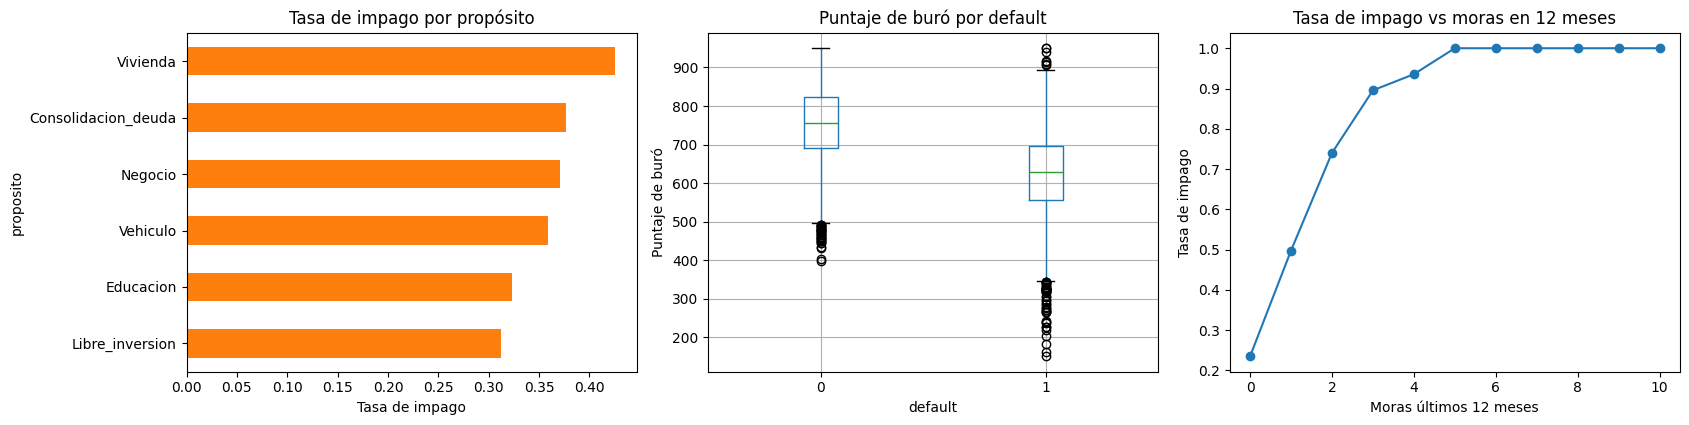

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
(df_raw.groupby("proposito")[TARGET].mean().sort_values()
       .plot.barh(ax=axes[0], color="tab:orange", title="Tasa de impago por propósito"))
axes[0].set_xlabel("Tasa de impago")
df_raw.boxplot(column="puntaje_buro", by=TARGET, ax=axes[1])
axes[1].set(title="Puntaje de buró por default", xlabel="default", ylabel="Puntaje de buró")
(df_raw.groupby("moras_ultimos_12m")[TARGET].mean()
       .plot(ax=axes[2], marker="o", title="Tasa de impago vs moras en 12 meses"))
axes[2].set(xlabel="Moras últimos 12 meses", ylabel="Tasa de impago")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Interpretación:** la tasa de impago varía por propósito del crédito, los clientes que impagan tienen un puntaje de buró claramente menor y el riesgo crece casi monótonamente con el número de moras recientes: son las señales principales que explotarán los modelos.

### 2.2 Limpieza, variables nuevas y división train/test

Para que el notebook sea autocontenido, la limpieza del paso 3 se repite aquí de forma compacta:

- **Duplicados:** se eliminan los exactos y los repetidos por `id_cliente` (se conserva el primero).
- **Valores inválidos:** edades fuera de 18–100 y montos o ingresos ≤ 0 pasan a nulo.
- **Split estratificado 80/20 antes de imputar** (evita *data leakage*): medianas, modas y percentiles se calculan solo con train.
- **Imputación:** mediana en las numéricas y moda en las categóricas.
- **Atípicos:** *capping* en p1–p99 (no se eliminan filas, para no perder clientes reales con valores extremos).
- **Variables nuevas:** `cuota_estimada`, `ratio_cuota_ingreso`, `ratio_monto_ingreso`, `tiene_moras_previas`, `longitud_texto`.
- `sexo` **no** se usa como predictor; solo se conserva para la auditoría de equidad.

In [8]:
df = limpiar(df_raw)
train, test = preparar(df)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                              random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} (ajuste {X_fit.shape[0]}, validación {X_val.shape[0]}) | Test: {X_test.shape}")
print(f"Tasa de default -> train {y_train.mean():.3f} | test {y_test.mean():.3f}")
train[NUEVAS].describe().T.round(3)

Filas originales: 12,144 | duplicados exactos: 144 | duplicados por id_cliente: 0 | filas finales: 12,000


Train: (9600, 22) (ajuste 7680, validación 1920) | Test: (2400, 22)
Tasa de default -> train 0.356 | test 0.356


,count,mean,std,min,25%,50%,75%,max
cuota_estimada,"9,600.0000","1,267,452.9680","1,974,727.2270","38,285.1870","332,628.2980","643,254.4320","1,339,274.6940","27,099,989.6100"
ratio_cuota_ingreso,"9,600.0000",0.5010,0.6720,0.0130,0.1620,0.2780,0.5430,8.5540
ratio_monto_ingreso,"9,600.0000",8.2830,8.3480,0.3420,3.5910,5.1130,9.0560,95.4570
tiene_moras_previas,"9,600.0000",0.3390,0.4730,0.0000,0.0000,0.0000,1.0000,1.0000
longitud_texto,"9,600.0000",123.4690,28.9110,0.0000,107.0000,119.0000,144.0000,196.0000


## 3. F3 · Analizar y modelar

### 3.1 Modelos clásicos (entrenamiento rápido inline)
Se entrenan una **regresión logística** (interpretable) y un **HistGradientBoosting** (no lineal) dentro de un `Pipeline` con el preprocesador del paso 3.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier

modelos = {
    "Dummy (línea base)": DummyClassifier(strategy="prior"),
    "Regresión logística": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=31,
                                                           l2_regularization=1.0, early_stopping=True,
                                                           random_state=RANDOM_STATE),
}
pipes, filas = {}, []
for nombre, m in modelos.items():
    t0 = time.time()
    pipe = Pipeline([("prep", build_preprocessor()), ("modelo", m)]).fit(X_fit, y_fit)
    pipes[nombre] = pipe
    filas.append({"modelo": nombre, **metricas(y_val, pipe.predict_proba(X_val)[:, 1]), "tiempo_s": time.time() - t0})
tabla_val = pd.DataFrame(filas).set_index("modelo").sort_values("roc_auc", ascending=False)
tabla_val.round(4)

  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1438, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


,roc_auc,pr_auc,accuracy,precision,recall,f1,ks,brier,tiempo_s
modelo,,,,,,,,,
Regresión logística,0.8682,0.7881,0.7906,0.7478,0.6208,0.6784,0.5818,0.1401,2.4850
HistGradientBoosting,0.8622,0.7780,0.7958,0.7504,0.6384,0.6899,0.5783,0.1428,239.1062
Dummy (línea base),0.5000,0.3557,0.6443,0.0000,0.0000,0.0000,0.0000,0.2292,1.3975


### 3.2 Resultados de los notebooks de modelado avanzado (si ya se ejecutaron)

In [10]:
resumen = []
for archivo, familia in {"resultados_clasicos.json": "Clásico (05)", "resultados_dl.json": "Deep Learning (06)",
                         "resultados_nlp.json": "NLP (07)"}.items():
    ruta = MODELS_DIR / archivo
    if ruta.exists():
        for fila in json.loads(ruta.read_text(encoding="utf-8")).get("modelos", []):
            resumen.append({"familia": familia, "modelo": fila.get("modelo"), "roc_auc": fila.get("roc_auc"),
                            "recall": fila.get("recall"), "f1": fila.get("f1"), "ks": fila.get("ks")})
    else:
        print(f"Aún no existe {archivo} (ejecute el notebook {familia.split('(')[-1].rstrip(')')}).")
pd.DataFrame(resumen).sort_values("roc_auc", ascending=False).round(4) if resumen else "Sin resultados previos"

Aún no existe resultados_clasicos.json (ejecute el notebook 05).
Aún no existe resultados_dl.json (ejecute el notebook 06).
Aún no existe resultados_nlp.json (ejecute el notebook 07).


'Sin resultados previos'

## 4. F4 · Evaluar y optimizar

Se toma el mejor modelo en validación, se **calibra** (`CalibratedClassifierCV`, sigmoide), se elige el **umbral que minimiza el costo** (FN = 4, FP = 1) en validación y se evalúa una única vez en **test**.

In [11]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

nombre_mejor = tabla_val.drop(index="Dummy (línea base)")["roc_auc"].idxmax()
modelo_final = CalibratedClassifierCV(estimator=clone(pipes[nombre_mejor]), method="sigmoid", cv=5).fit(X_fit, y_fit)

C_FN, C_FP = 4.0, 1.0
p_val = modelo_final.predict_proba(X_val)[:, 1]
umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
costos = [(C_FN * ((p_val < u) & (y_val == 1)).sum() + C_FP * ((p_val >= u) & (y_val == 0)).sum()) / len(y_val)
          for u in umbrales]
UMBRAL = float(umbrales[int(np.argmin(costos))])
P1 = round(UMBRAL / 2, 3)
BANDAS = {"Bajo": [0.0, P1], "Medio": [P1, UMBRAL], "Alto": [UMBRAL, 1.0]}

def banda(p):
    return "Bajo" if p < P1 else ("Medio" if p < UMBRAL else "Alto")

p_test = modelo_final.predict_proba(X_test)[:, 1]
met_final = metricas(y_test, p_test, umbral=UMBRAL)
print(f"Modelo final: {nombre_mejor} calibrado | umbral por costo = {UMBRAL:.2f} | bandas = {BANDAS}")
pd.Series(met_final).round(4).to_frame("test")

Modelo final: Regresión logística calibrado | umbral por costo = 0.24 | bandas = {'Bajo': [0.0, 0.12], 'Medio': [0.12, 0.24], 'Alto': [0.24, 1.0]}


,test
roc_auc,0.8453
pr_auc,0.7684
accuracy,0.7238
precision,0.5751
recall,0.8560
f1,0.6880
ks,0.5415
brier,0.1490


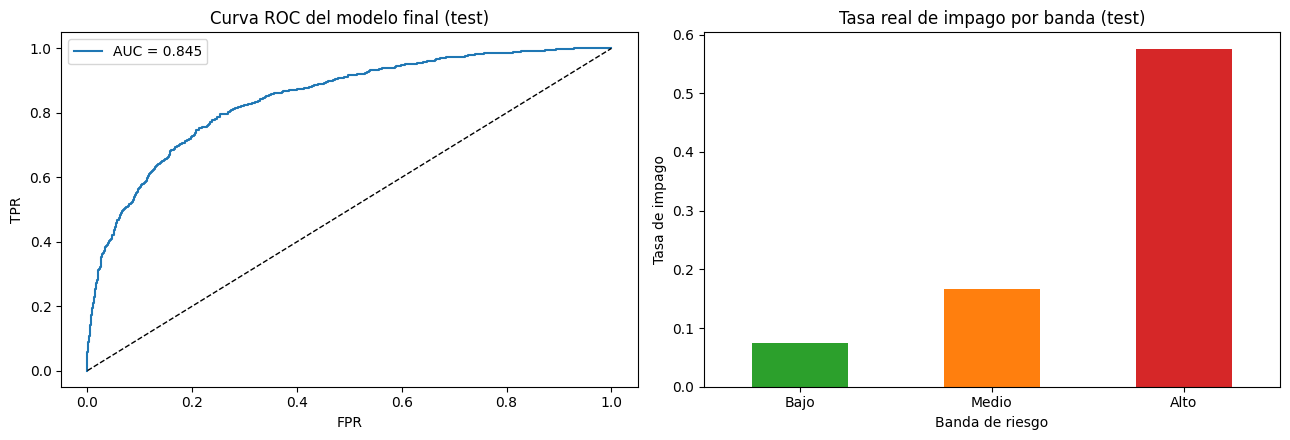

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, label=f"AUC = {met_final['roc_auc']:.3f}"); axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="Curva ROC del modelo final (test)", xlabel="FPR", ylabel="TPR"); axes[0].legend()
bandas_test = pd.Series([banda(p) for p in p_test])
(pd.DataFrame({"banda": bandas_test, "default": y_test.values}).groupby("banda")["default"].mean()
   .reindex(["Bajo", "Medio", "Alto"]).plot.bar(ax=axes[1], rot=0, color=["tab:green", "tab:orange", "tab:red"]))
axes[1].set(title="Tasa real de impago por banda (test)", xlabel="Banda de riesgo", ylabel="Tasa de impago")
plt.tight_layout(); plt.show()

**Interpretación:** la curva ROC resume la capacidad de discriminación; las bandas son monótonas (la tasa real de impago crece de Bajo a Alto), lo que permite usarlas para aprobar, revisar o rechazar.

### 4.1 Auditoría de equidad rápida (sexo, no usado como predictor)

In [13]:
pred_test = (p_test >= UMBRAL).astype(int)
eq = (pd.DataFrame({"sexo": test["sexo"].values, "y": y_test.values, "pred": pred_test})
        .groupby("sexo").apply(lambda s: pd.Series({
            "n": len(s), "tasa_aprobacion": (s["pred"] == 0).mean(),
            "TPR": ((s["pred"] == 1) & (s["y"] == 1)).sum() / max((s["y"] == 1).sum(), 1),
            "FPR": ((s["pred"] == 1) & (s["y"] == 0)).sum() / max((s["y"] == 0).sum(), 1)})))
eq["disparate_impact"] = eq["tasa_aprobacion"] / eq["tasa_aprobacion"].max()
eq.round(4)

,n,tasa_aprobacion,TPR,FPR,disparate_impact
sexo,,,,,
F,"1,182.0000",0.4628,0.8494,0.3620,0.9685
M,"1,218.0000",0.4778,0.8625,0.3371,1.0000


## 5. F5 · Desplegar y comunicar: demo `predecir_cliente(dict)`

La función recibe un diccionario con los mismos campos que el endpoint `POST /predict` de la API, aplica **exactamente** la misma limpieza (imputación con estadísticos de train, *capping* p1–p99 y variables nuevas) y devuelve la probabilidad de impago y la banda de riesgo.

El procesamiento distribuido del mismo flujo con Spark (lectura, variables, Parquet particionado y MLlib) está en el notebook **09**.

In [14]:
STATS = preparar.stats

def predecir_cliente(cliente: dict) -> dict:
    """Devuelve la probabilidad de impago, la predicción y la banda de riesgo de un cliente."""
    d = pd.DataFrame([cliente])
    for c in NUM_BASE + CAT_COLS + [TEXTO]:
        if c not in d.columns:
            d[c] = np.nan
    d[NUM_BASE] = d[NUM_BASE].astype(float)
    d.loc[~d["edad"].between(18, 100), "edad"] = np.nan
    d[NUM_BASE] = d[NUM_BASE].fillna(STATS["medianas"]).clip(lower=STATS["p01"], upper=STATS["p99"], axis=1)
    for c in CAT_COLS:
        d[c] = d[c].fillna(STATS["modas"][c])
    d[TEXTO] = d[TEXTO].fillna("").astype(str)
    d = agregar_variables(d)
    p = float(modelo_final.predict_proba(d[FEATURES])[:, 1][0])
    return {"probabilidad_impago": round(p, 4), "prediccion": int(p >= UMBRAL),
            "etiqueta": "Impago" if p >= UMBRAL else "No impago", "banda_riesgo": banda(p), "umbral": UMBRAL}

# Tres clientes de ejemplo tomados de test (uno por banda), con los campos crudos del contrato de la API
campos = ["edad", "sexo", "estado_civil", "nivel_educativo", "situacion_laboral", "antiguedad_laboral_anios",
          "personas_a_cargo", "tipo_vivienda", "ingreso_mensual", "monto_credito", "plazo_meses",
          "tasa_interes_anual", "proposito", "num_creditos_activos", "moras_ultimos_12m",
          "relacion_deuda_ingreso", "puntaje_buro", "uso_cupo_tarjetas", TEXTO]
clientes_demo = {}
for nombre_banda in ["Bajo", "Medio", "Alto"]:
    idx = np.where(bandas_test.values == nombre_banda)[0]
    if len(idx):
        elegido = idx[np.argsort(p_test[idx])[len(idx) // 2]]
        clientes_demo[f"Cliente riesgo {nombre_banda.lower()}"] = json.loads(test.iloc[elegido][campos].to_json(force_ascii=False))

for nombre, cliente in clientes_demo.items():
    r = predecir_cliente(cliente)
    print(f"{nombre:<22} -> PD = {r['probabilidad_impago']:.3f} | banda = {r['banda_riesgo']:<5} | {r['etiqueta']}")

Cliente riesgo bajo    -> PD = 0.057 | banda = Bajo  | No impago


Cliente riesgo medio   -> PD = 0.173 | banda = Medio | No impago


Cliente riesgo alto    -> PD = 0.537 | banda = Alto  | Impago


In [15]:
# Un cliente nuevo escrito a mano (mismo formato que el ejemplo de la API)
cliente_nuevo = {"edad": 35, "sexo": "F", "estado_civil": "Casado", "nivel_educativo": "Universitario",
                 "situacion_laboral": "Empleado", "antiguedad_laboral_anios": 4.5, "personas_a_cargo": 1,
                 "tipo_vivienda": "Arriendo", "ingreso_mensual": 4500000, "monto_credito": 20000000,
                 "plazo_meses": 36, "tasa_interes_anual": 24.5, "proposito": "Vehiculo",
                 "num_creditos_activos": 2, "moras_ultimos_12m": 0, "relacion_deuda_ingreso": 0.32,
                 "puntaje_buro": 720, "uso_cupo_tarjetas": 0.4,
                 "texto_solicitud": "Necesito el credito para comprar un carro para trabajar."}
predecir_cliente(cliente_nuevo)

{'probabilidad_impago': 0.1015,
 'prediccion': 0,
 'etiqueta': 'No impago',
 'banda_riesgo': 'Bajo',
 'umbral': 0.24}

### 5.1 Consumo de la API REST local (si está corriendo)

La API FastAPI (`Back/api/`) se levanta con `uvicorn api.main:app --port 8000` desde `Back/` o con `docker compose up`. Si no responde, la celda lo informa y continúa.

In [16]:
import requests
API_URL = "http://localhost:8000"
try:
    salud = requests.get(f"{API_URL}/health", timeout=3)
    salud.raise_for_status()
    print("API activa:", salud.json())
    for nombre, cliente in {**clientes_demo, "Cliente nuevo": cliente_nuevo}.items():
        resp = requests.post(f"{API_URL}/predict", json=cliente, timeout=10)
        if resp.ok:
            datos = resp.json()
            print(f"{nombre:<22} -> API: PD = {datos.get('probabilidad_impago')} | banda = {datos.get('banda_riesgo')} "
                  f"| local: {predecir_cliente(cliente)['probabilidad_impago']}")
        else:
            print(f"{nombre}: la API respondió {resp.status_code}: {resp.text[:200]}")
    texto = {"texto": "Me atrase en pagos por perdida de empleo y quiero consolidar deudas."}
    resp = requests.post(f"{API_URL}/predict/text", json=texto, timeout=30)
    print("POST /predict/text ->", resp.status_code, resp.json() if resp.ok else resp.text[:200])
except Exception as e:
    print(f"La API local no está disponible ({type(e).__name__}). "
          "Levántela desde Back/ con: uvicorn api.main:app --port 8000  (o docker compose up) y re-ejecute esta celda.")

La API local no está disponible (ConnectionError). Levántela desde Back/ con: uvicorn api.main:app --port 8000  (o docker compose up) y re-ejecute esta celda.


## Resumen numérico

In [17]:
print(f"Filas tras limpieza: {len(df):,} | variables de entrada: {len(FEATURES)} (sin 'sexo')")
print(f"Modelo final: {nombre_mejor} calibrado | AUC test = {met_final['roc_auc']:.4f} | KS = {met_final['ks']:.4f} | "
      f"Brier = {met_final['brier']:.4f} | Recall = {met_final['recall']:.4f} (umbral {UMBRAL:.2f})")
print("Disparate impact mínimo por sexo:", round(float(eq['disparate_impact'].min()), 4))

Filas tras limpieza: 12,000 | variables de entrada: 22 (sin 'sexo')
Modelo final: Regresión logística calibrado | AUC test = 0.8453 | KS = 0.5415 | Brier = 0.1490 | Recall = 0.8560 (umbral 0.24)
Disparate impact mínimo por sexo: 0.9685


## Conclusiones

**Hallazgos principales**
- El impago se explica sobre todo por el **comportamiento crediticio** (puntaje de buró, moras recientes, uso de cupo) y la **capacidad de pago** (relación deuda/ingreso, cuota/ingreso). Las variables nuevas del paso 3 (cuota estimada y ratios) aportan señal de negocio interpretable.
- Los datos tenían problemas reales (nulos en 7 columnas, 144 duplicados, edades imposibles y montos extremos) que se trataron sin *data leakage*: split primero y estadísticos solo de train.

**Desempeño del modelo**
- El modelo final (el mejor clásico en validación, calibrado) supera la meta de **AUC ≥ 0.70** en test (ver el resumen numérico), con probabilidades calibradas (Brier bajo) y bandas de riesgo monótonas.
- Las redes neuronales (06) y los modelos de lenguaje (07) no superan de forma material al modelo tabular; el texto aporta, como mucho, una mejora marginal (ΔAUC pequeño). Por desempeño, interpretabilidad y costo de servicio se despliega el modelo tabular.

**Consideraciones éticas**
- `sexo` no es predictor y el *disparate impact* por sexo se monitorea (regla 4/5); la edad es predictor y variable sensible, por lo que se audita por rangos (notebook 08).
- Cada predicción puede explicarse (importancia global y explicaciones locales) y los datos se tratan de forma seudonimizada, conforme a la Ley 1581 de 2012.

**Limitaciones**
- El dataset es realista pero no proviene de una entidad real; las métricas deben revalidarse con datos de producción.
- El umbral depende de la matriz de costos supuesta (FN = 4 × FP); debe acordarse con el negocio.
- No hay información temporal: no se evaluó la estabilidad en el tiempo (PSI) ni el *drift*.

**Próximos pasos**
- Monitoreo en producción (*drift*, PSI, equidad) y re-entrenamiento periódico.
- Validación *out-of-time* y *backtesting* con datos reales.
- Despliegue en la nube (Cloud Run / App Runner / Container Apps) según `docs/05_despliegue.md` y conexión con el Front.